# Heart Disease Prediction System — Project Part 1
**Course:** AI2002 – Artificial Intelligence | **Instructor:** Bushra Rashid | **Institution:** FAST-NUCES

| Name | Roll No |
|---|---|
| Muhammad Umar Bin Naeem | 24L-0582 |
| Waleed Bin Omer | 24L-0571 |
| Anas Irfan | 24L-0747 |

---
## 1. Dataset Description and Features

**Dataset:** Merged UCI Heart Disease Dataset (extended Cleveland variant)  
**Source:** UCI Machine Learning Repository  
**Domain:** Medical / Cardiovascular Health  
**Task:** Binary Classification — predict presence (1) or absence (0) of heart disease  
**Size:** 2,181 records × 14 columns

| Feature | Type | Description |
|---|---|---|
| age | Numerical | Patient age in years |
| sex | Categorical | 1 = Male, 0 = Female |
| cp | Categorical | Chest pain type (0–3) |
| trestbps | Numerical | Resting blood pressure (mm Hg) |
| chol | Numerical | Serum cholesterol (mg/dl) |
| fbs | Categorical | Fasting blood sugar > 120 mg/dl (1=True, 0=False) |
| restecg | Categorical | Resting ECG results (0–2) |
| thalachh | Numerical | Maximum heart rate achieved |
| exang | Categorical | Exercise-induced angina (1=Yes, 0=No) |
| oldpeak | Numerical | ST depression induced by exercise |
| slope | Categorical | Slope of peak exercise ST segment (0–2) |
| ca | Numerical | Number of major vessels (0–4) colored by fluoroscopy |
| thal | Categorical | Thalassemia type (1–3) |
| target | Categorical | **Target**: 1 = Disease, 0 = No Disease |

---
## 2. Preprocessing with Pandas

### 2.1 Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


### 2.2 Load the Data

In [4]:
df = pd.read_csv('raw_merged_heart_dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (2181, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 2.3 Missing Values

In [5]:
# The dataset encodes missing values as '?' — replace with NaN
df.replace('?', np.nan, inplace=True)

# Convert affected columns to numeric
cols_to_fix = ['trestbps','chol','fbs','restecg','thalachh','exang','slope','ca','thal']
for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
age           0
sex           0
cp            0
trestbps      1
chol         23
fbs           8
restecg       1
thalachh      1
exang         1
oldpeak       0
slope       190
ca          291
thal        266
target        0
dtype: int64


In [6]:
# Impute: binary columns → mode, continuous/ordinal → median
for col in ['fbs', 'restecg', 'exang']:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in ['trestbps','chol','thalachh','slope','ca','thal']:
    df[col] = df[col].fillna(df[col].median())

print('Missing values after imputation:', df.isnull().sum().sum())

Missing values after imputation: 0


### 2.4 Data Type Conversion

In [7]:
# Convert float columns that represent integers back to int
int_cols = ['trestbps','chol','fbs','restecg','thalachh','exang','slope','ca','thal']
for col in int_cols:
    df[col] = df[col].astype(int)

print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


### 2.5 Outliers — IQR Detection & Capping

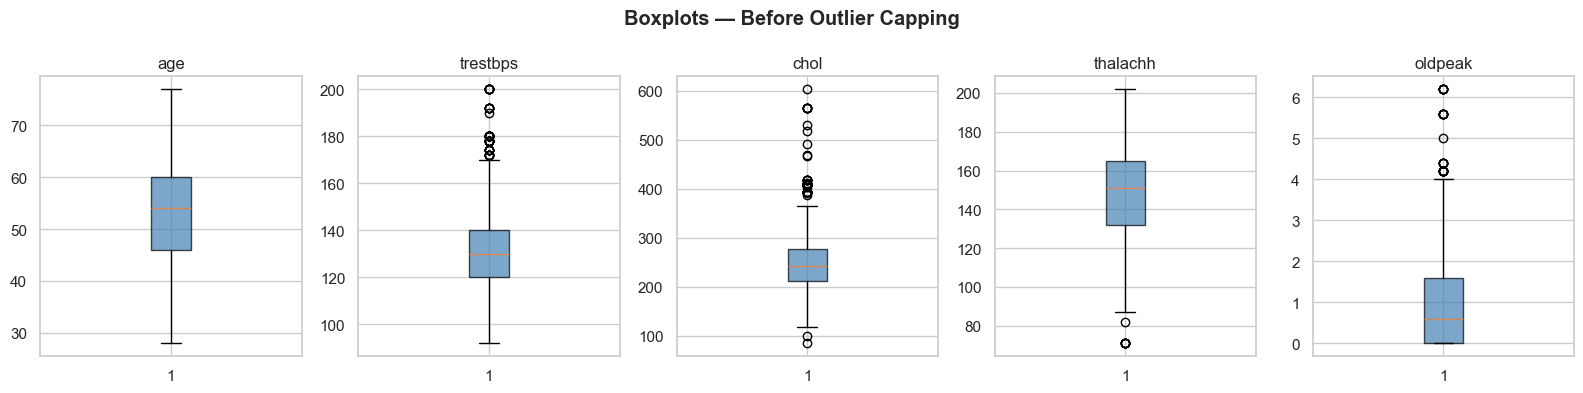

Outliers capped via IQR method.


In [8]:
continuous = ['age', 'trestbps', 'chol', 'thalachh', 'oldpeak']

# Visualise outliers with boxplots before capping
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, col in enumerate(continuous):
    axes[i].boxplot(df[col], patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.7))
    axes[i].set_title(col)
plt.suptitle('Boxplots — Before Outlier Capping', fontweight='bold')
plt.tight_layout()
plt.show()

# Cap outliers at 1.5×IQR fences
for col in continuous:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(lower=Q1 - 1.5*IQR, upper=Q3 + 1.5*IQR)
print('Outliers capped via IQR method.')

### 2.6 Dimensionality

In [9]:
print(f'DataFrame shape: {df.shape}')
print(f'  {df.shape[0]} rows (samples)')
print(f'  {df.shape[1]} columns (features)')

DataFrame shape: (2181, 14)
  2181 rows (samples)
  14 columns (features)


### 2.7 Descriptive Statistics

In [10]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
count,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.00,2181.0
mean,53.48,0.69,1.25,131.32,245.98,0.14,0.55,148.10,0.33,0.98,1.41,0.63,2.62,0.5
std,9.19,0.46,1.12,16.56,48.49,0.34,0.63,23.21,0.47,1.09,0.60,0.98,1.24,0.5
min,28.00,0.00,0.00,92.00,113.50,0.00,0.00,82.50,0.00,0.00,0.00,0.00,0.00,0.0
25%,46.00,0.00,0.00,120.00,211.00,0.00,0.00,132.00,0.00,0.00,1.00,0.00,2.00,0.0
50%,54.00,1.00,1.00,130.00,242.00,0.00,0.00,151.00,0.00,0.60,1.00,0.00,2.00,0.0
75%,60.00,1.00,2.00,140.00,276.00,0.00,1.00,165.00,1.00,1.60,2.00,1.00,3.00,1.0
max,77.00,1.00,3.00,170.00,373.50,1.00,2.00,202.00,1.00,4.00,3.00,4.00,7.00,1.0


---
## 3. Data Visualisation

### 3.1 Numerical Features — Histograms

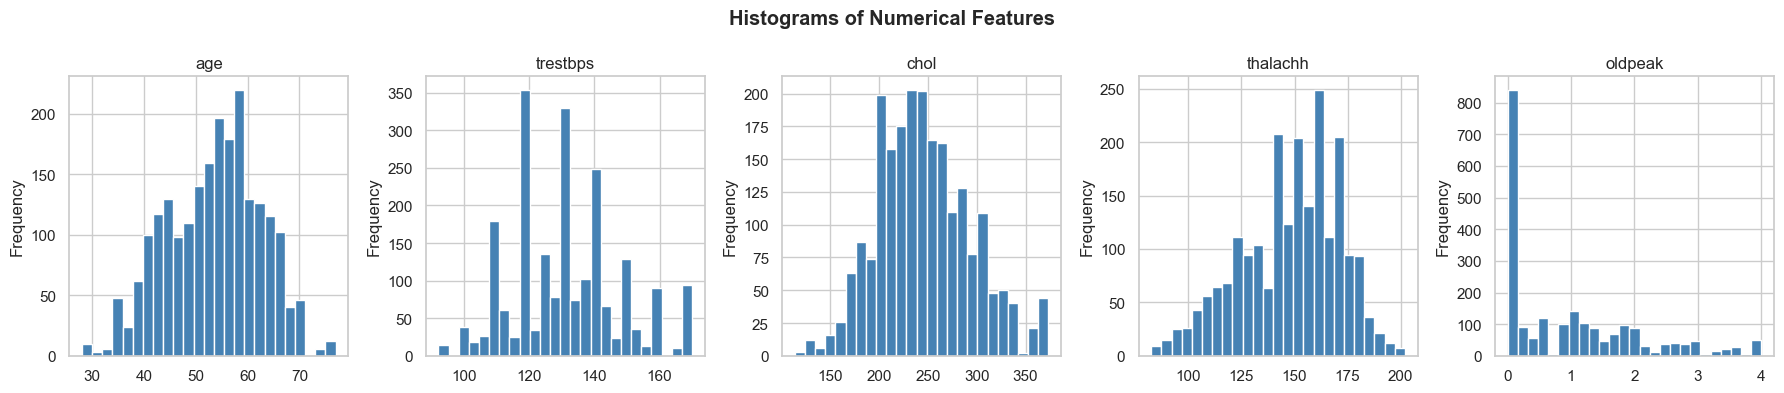

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(continuous):
    axes[i].hist(df[col], bins=25, color='steelblue', edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_ylabel('Frequency')
plt.suptitle('Histograms of Numerical Features', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Categorical Features — Bar Charts

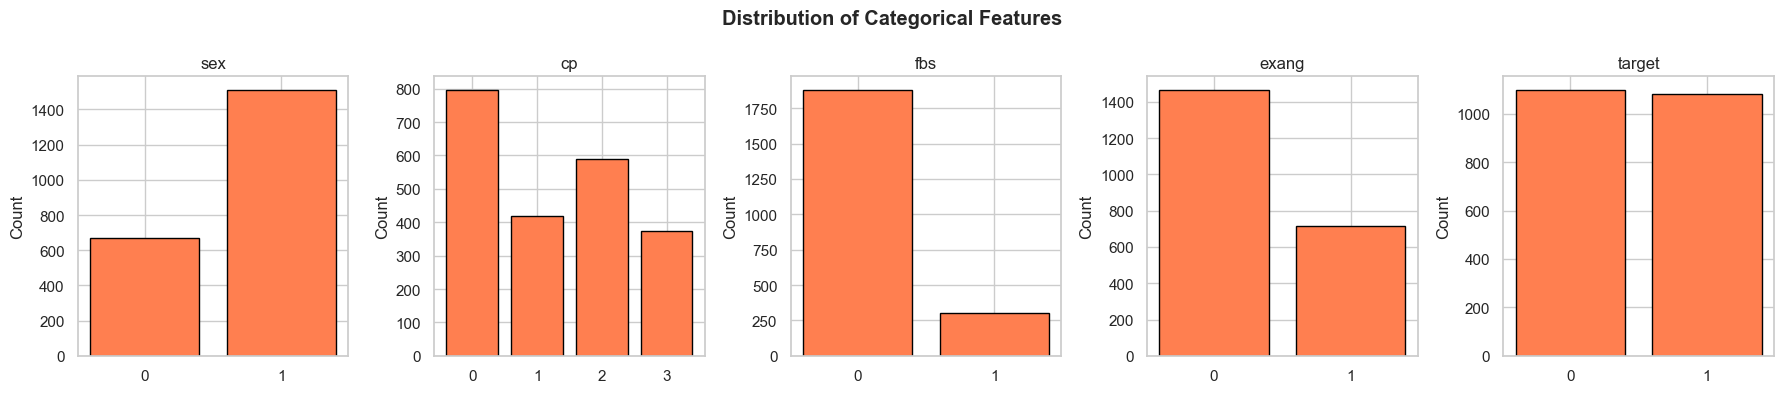

In [12]:
cat_cols = ['sex', 'cp', 'fbs', 'exang', 'target']

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(cat_cols):
    counts = df[col].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color='coral', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_ylabel('Count')
plt.suptitle('Distribution of Categorical Features', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.3 Scatter Plots

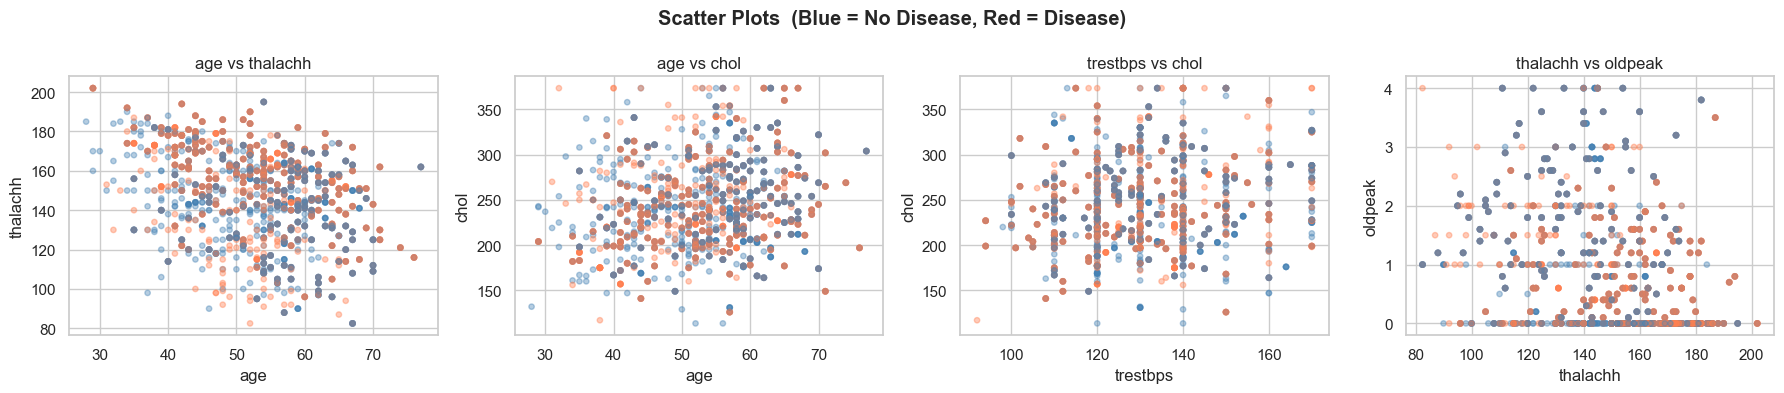

In [13]:
pairs = [('age','thalachh'), ('age','chol'), ('trestbps','chol'), ('thalachh','oldpeak')]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, (x, y) in enumerate(pairs):
    colors = df['target'].map({0:'steelblue', 1:'coral'})
    axes[i].scatter(df[x], df[y], c=colors, alpha=0.4, s=15)
    axes[i].set_xlabel(x)
    axes[i].set_ylabel(y)
    axes[i].set_title(f'{x} vs {y}')
plt.suptitle('Scatter Plots  (Blue = No Disease, Red = Disease)', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4 Pair Plot

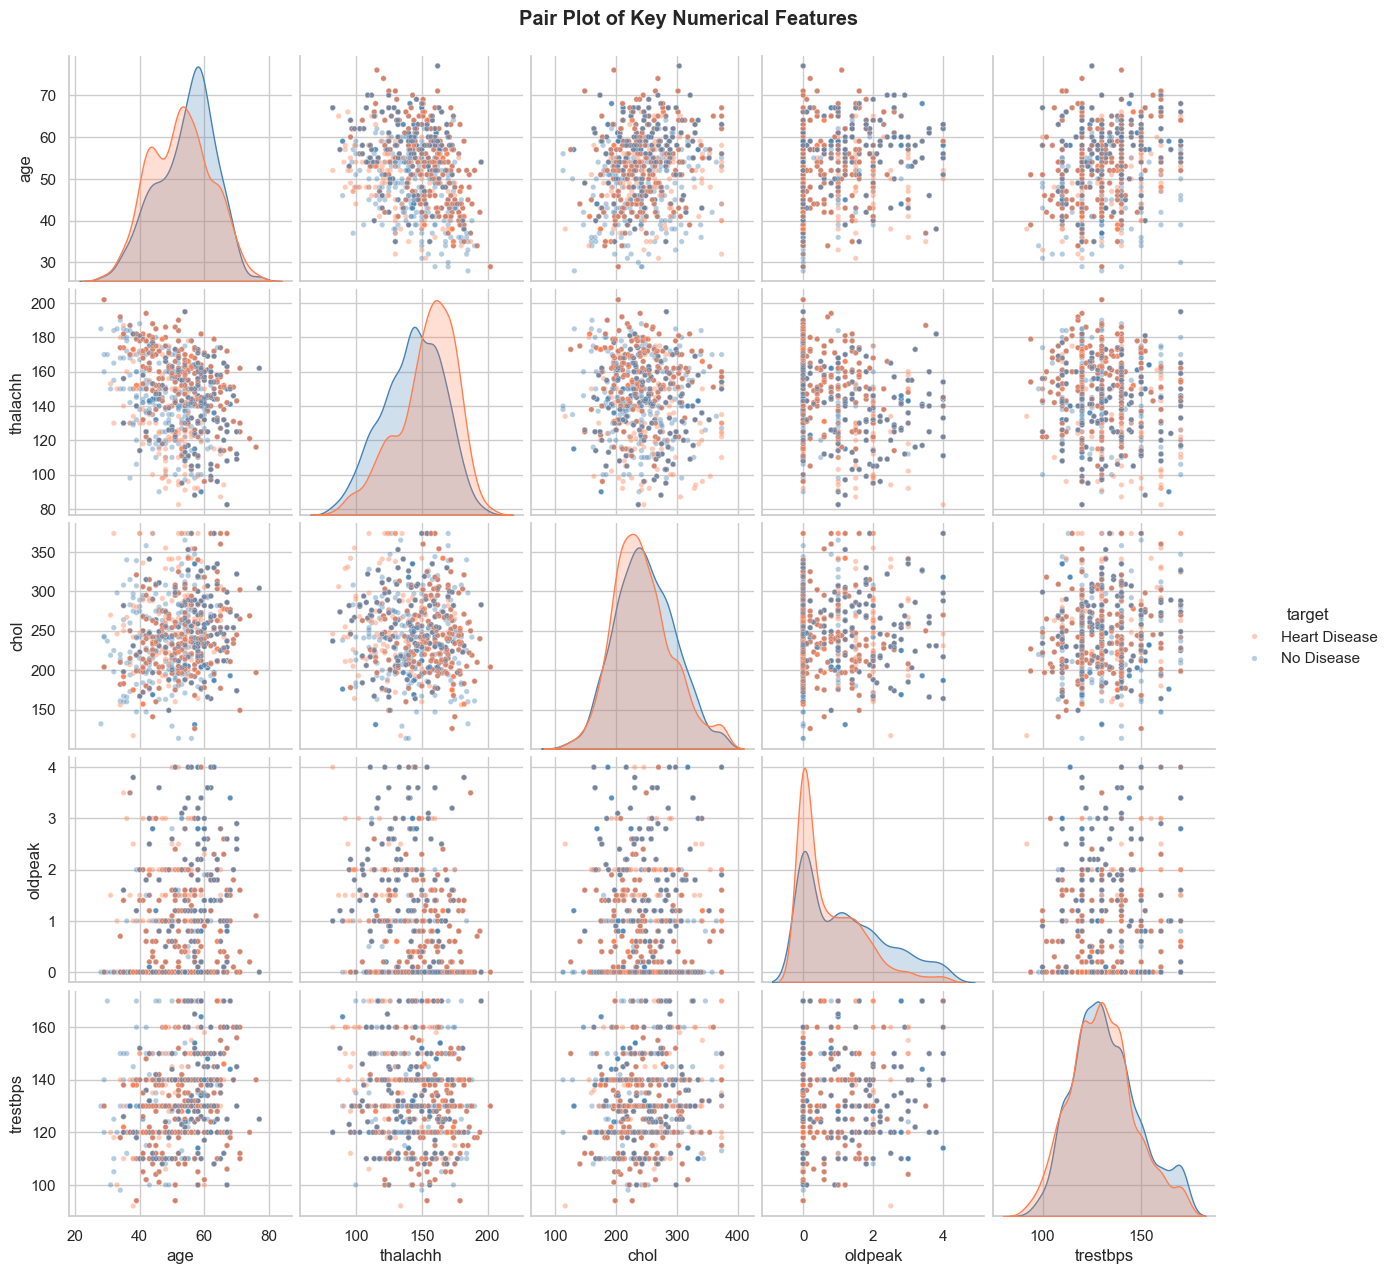

In [14]:
pair_df = df[['age','thalachh','chol','oldpeak','trestbps','target']].copy()
pair_df['target'] = pair_df['target'].map({0:'No Disease', 1:'Heart Disease'})

sns.pairplot(pair_df, hue='target',
             palette={'No Disease':'steelblue', 'Heart Disease':'coral'},
             plot_kws={'alpha':0.4, 's':15},
             diag_kind='kde')
plt.suptitle('Pair Plot of Key Numerical Features', y=1.02, fontweight='bold')
plt.show()

---
## 4. Methodology

Two models will be used in this project:

**Model 1 — Logistic Regression** *(implemented below)*  
A linear probabilistic classifier designed for binary classification. Produces interpretable coefficients that reveal which clinical features drive heart disease risk. Serves as a strong, fast baseline.

**Model 2 — Random Forest Classifier** *(Part 2)*  
An ensemble of decision trees using bagging. Captures non-linear feature interactions, is robust to outliers, and produces built-in feature importance rankings — all valuable for medical classification tasks.

---
## 5. Model 1 — Logistic Regression

In [15]:
# Train/Test Split + Scaling
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Train size: {X_train_sc.shape},  Test size: {X_test_sc.shape}')

Train size: (1744, 13),  Test size: (437, 13)


In [16]:
# Train and evaluate
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)
y_pred = lr.predict(X_test_sc)

print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['No Disease','Heart Disease']))

Accuracy: 0.7346

               precision    recall  f1-score   support

   No Disease       0.75      0.70      0.73       220
Heart Disease       0.72      0.77      0.74       217

     accuracy                           0.73       437
    macro avg       0.74      0.73      0.73       437
 weighted avg       0.74      0.73      0.73       437



In [17]:
# 5-Fold Cross-Validation
pipe = Pipeline([('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=1000, random_state=42))])
cv_scores = cross_val_score(pipe, X, y, cv=5, scoring='accuracy')
print(f'CV Scores:  {cv_scores.round(4)}')
print(f'Mean: {cv_scores.mean():.4f}   Std: {cv_scores.std():.4f}')

CV Scores:  [0.8146 0.8073 0.7431 0.4587 0.6743]
Mean: 0.6996   Std: 0.1307


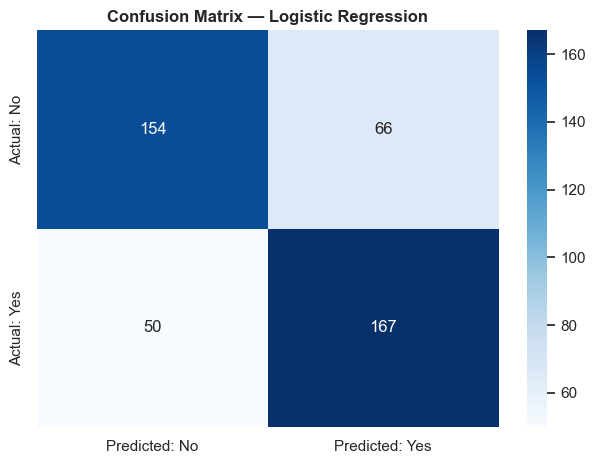

In [18]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: No','Predicted: Yes'],
            yticklabels=['Actual: No','Actual: Yes'])
plt.title('Confusion Matrix — Logistic Regression', fontweight='bold')
plt.tight_layout()
plt.show()

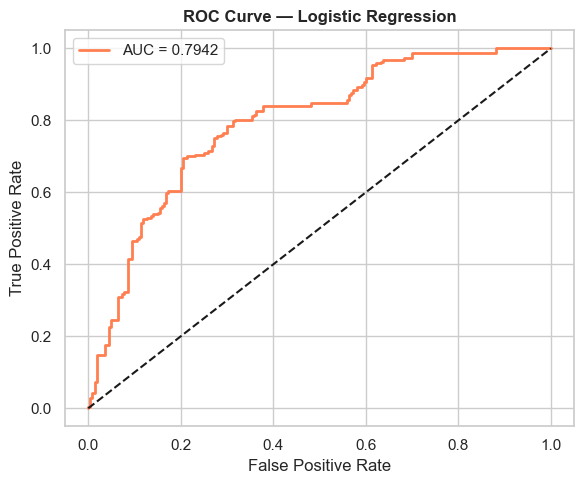

In [19]:
# ROC Curve
y_prob = lr.predict_proba(X_test_sc)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='coral', lw=2, label=f'AUC = {roc_auc:.4f}')
plt.plot([0,1],[0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Logistic Regression', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()